# 06 · Robustez: os resultados dependem do portal, das duplicatas ou dos textos curtos?

As limitações da Seção 3.6 apontam três riscos: (c) a amostra depende dos portais (LinkedIn = ~63%), (d) o dicionário depende do texto disponível,
e há anúncios que se repetem (mesmo título e empresa em várias cidades). Este notebook **refaz as estimativas principais** em cinco cenários
e mostra se a conclusão muda.

| Cenário | O que faz |
|---|---|
| **Base** | amostra do artigo (descrição ≥ 200 caracteres) |
| **Sem LinkedIn** | retira o portal dominante |
| **Só LinkedIn** | mostra o quanto o portal sozinho "puxa" o resultado |
| **Sem repetidos** | mantém um anúncio por par título + empresa |
| **Sem textos curtos** | descrições com ao menos 1.000 caracteres (após o recorte) |

**Critério de leitura:** se a estimativa de um cenário cai **dentro** do IC 95% da base, o resultado é estável àquela mudança;
se cai **fora**, a conclusão depende da escolha e deve vir acompanhada da sensibilidade.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
import analise_lib as L
L.estilo()
pd.set_option("display.max_colwidth", None, "display.width", 220)
df = L.carregar()
df["_chave"] = df["title"].fillna("").str.lower().str.strip() + "|" + df["company"].fillna("").str.lower().str.strip()
CEN = {
    "Base": df,
    "Sem LinkedIn": df[df.fonte != "linkedin"],
    "Só LinkedIn": df[df.fonte == "linkedin"],
    "Sem repetidos": df.drop_duplicates("_chave"),
    "Sem textos curtos": df[df.n_chars_aparado >= 1000],
}
display(pd.DataFrame({k: {"anúncios": len(v), "% da base": 100 * len(v) / len(df)} for k, v in CEN.items()}).T.style.format({"anúncios": "{:,.0f}", "% da base": "{:.0f}%"}))
print(f"Pares título+empresa repetidos: {df.duplicated('_chave').sum():,} anúncios a mais que o primeiro de cada par")

,anúncios,% da base
Base,"9,964",100%
Sem LinkedIn,"3,707",37%
Só LinkedIn,"6,257",63%
Sem repetidos,"8,036",81%
Sem textos curtos,"7,898",79%


Pares título+empresa repetidos: 1,928 anúncios a mais que o primeiro de cada par


## Métricas acompanhadas
Uma por objetivo: experiência (i), competências (ii), perfil (iii) e IA generativa (iv).

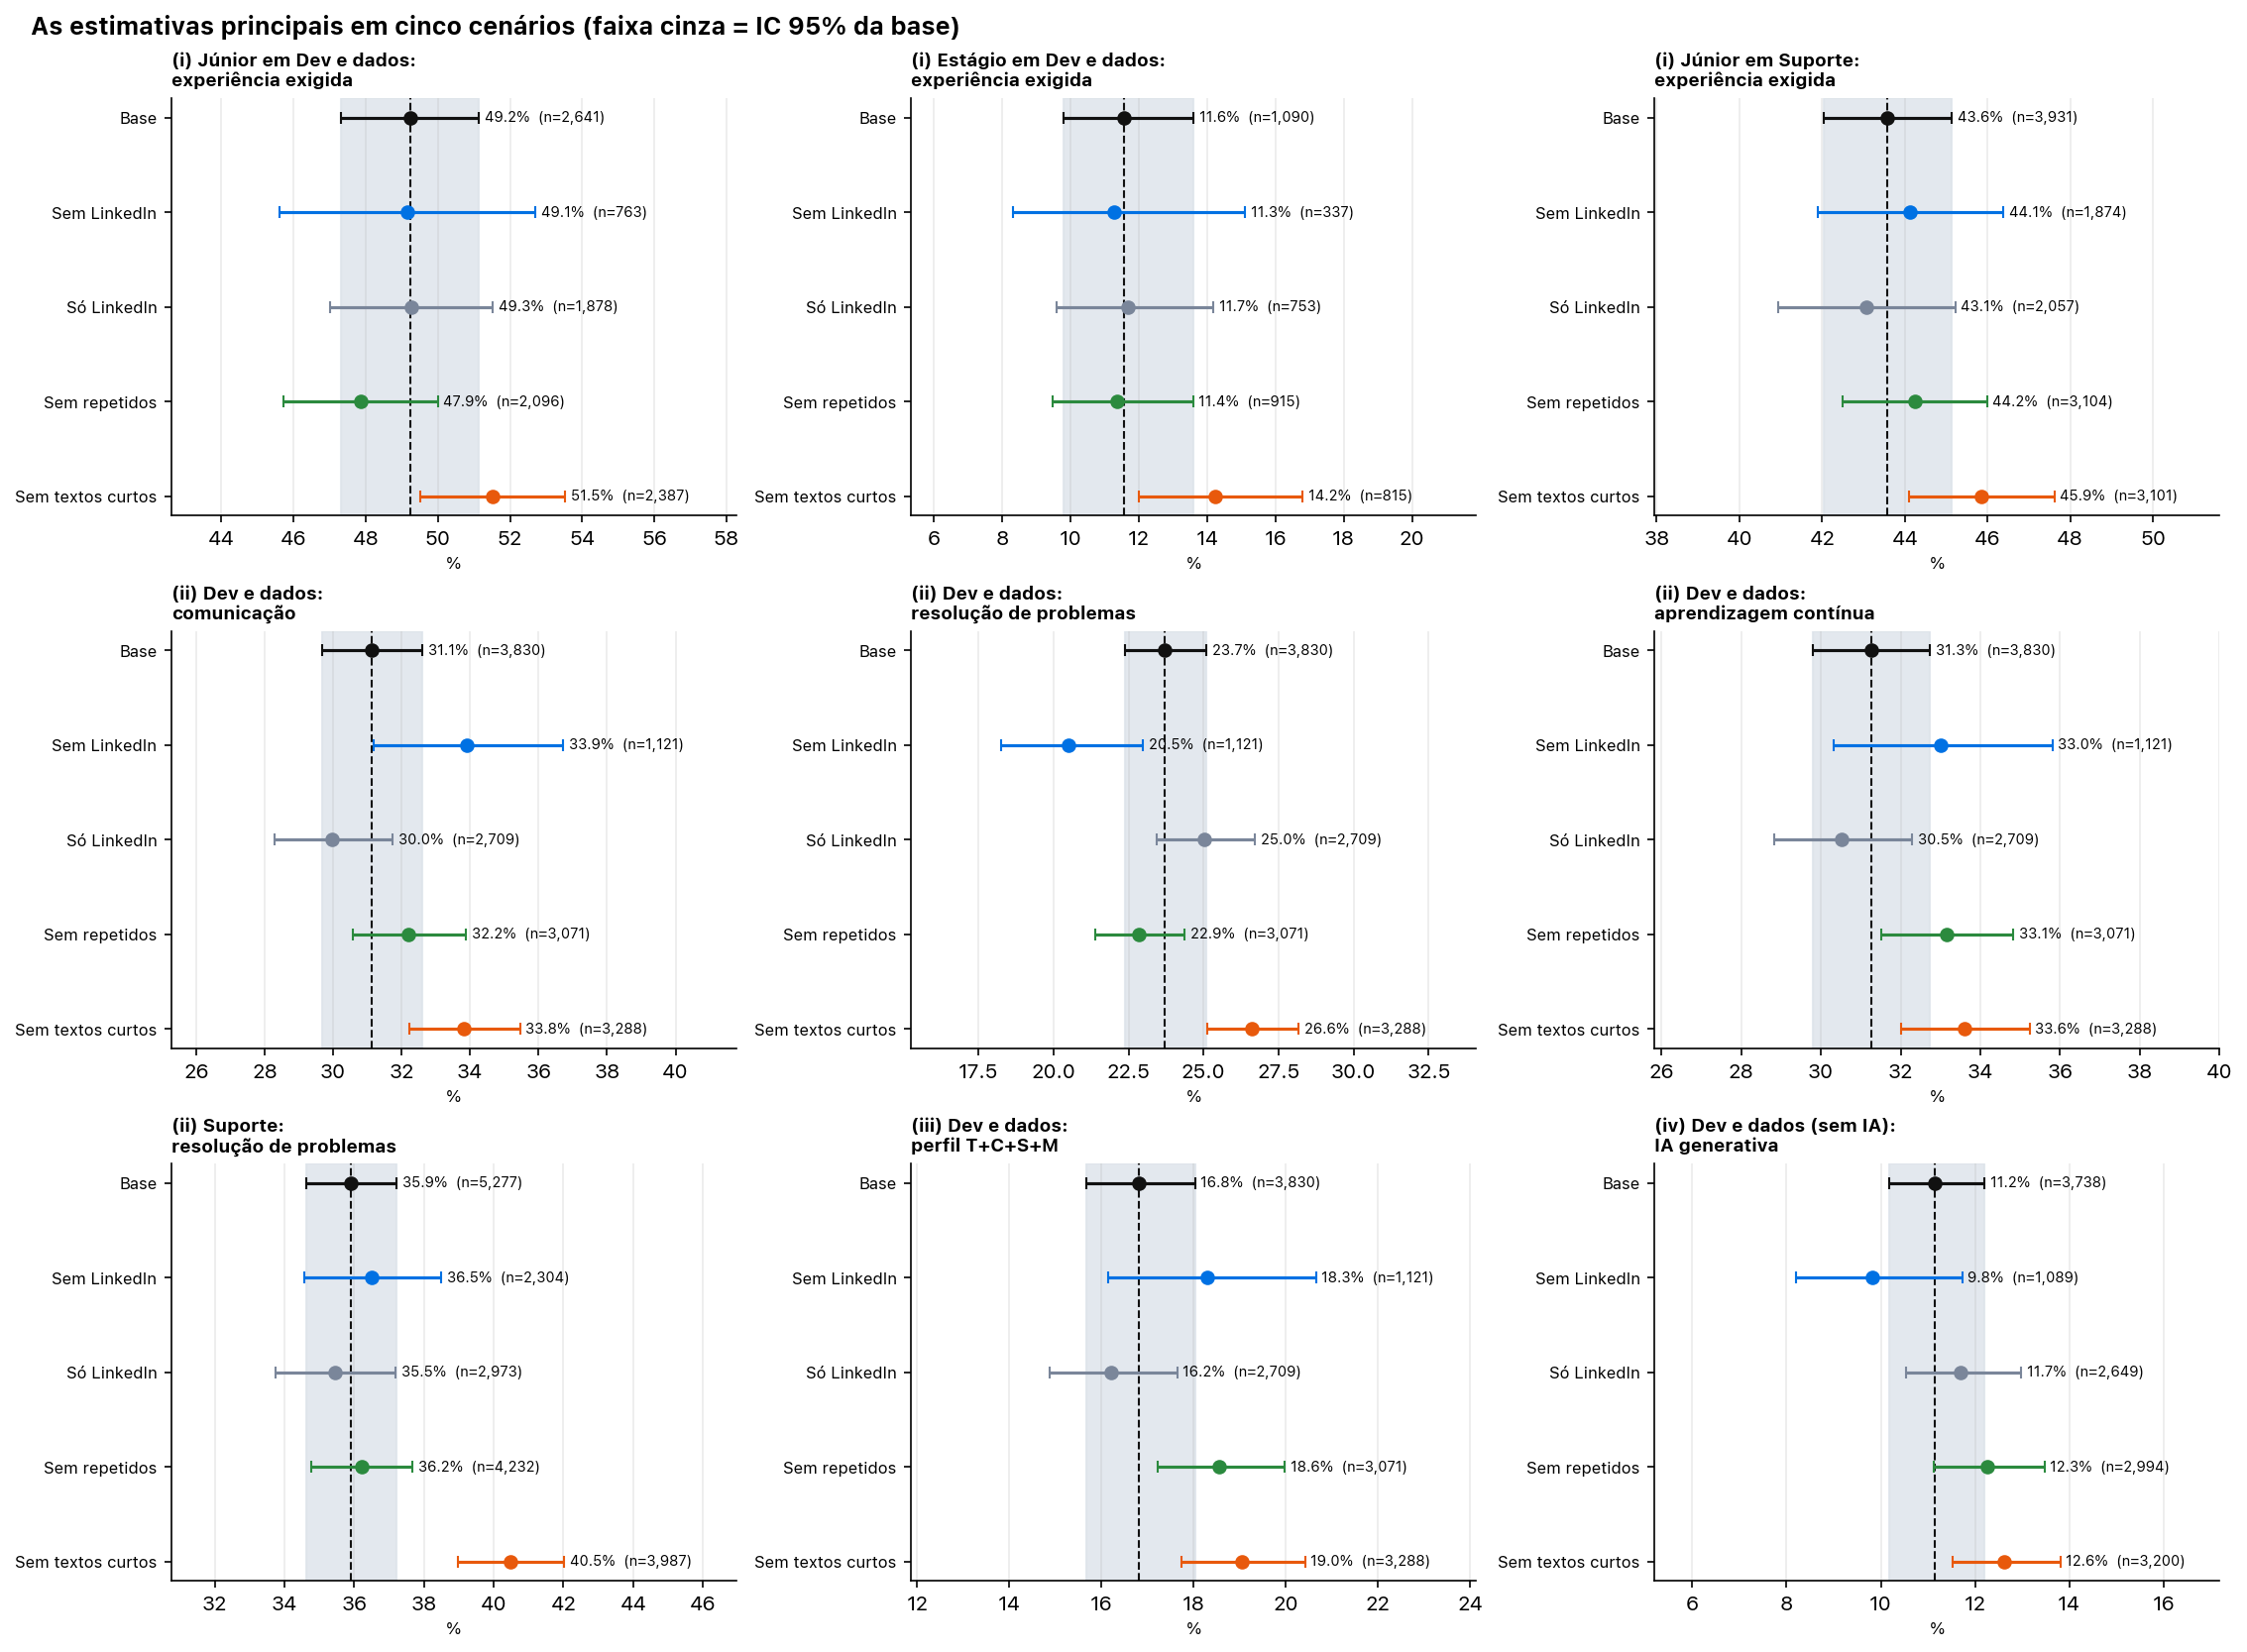

In [2]:
def f_exp(nivel, grupo):
    return lambda d: (d[(d.nivel == nivel) & (d.grupo == grupo)], "exp_obrigatoria")
def f_comp(k, grupo):
    return lambda d: (d[d.grupo == grupo], f"c_{k}")
def f_ia(d):
    return d[(d.grupo == L.G_DEV) & (d.area != "Inteligência Artificial")], "genai"
def f_perfil(d):
    s = d[d.grupo == L.G_DEV].copy(); s["tcsm"] = s.d_tecnica & s.d_cog & s.d_soc & s.d_met
    return s, "tcsm"
METRICAS = {
    "(i) Júnior em Dev e dados:\nexperiência exigida": f_exp("Júnior", L.G_DEV),
    "(i) Estágio em Dev e dados:\nexperiência exigida": f_exp("Estágio", L.G_DEV),
    "(i) Júnior em Suporte:\nexperiência exigida": f_exp("Júnior", L.G_SUP),
    "(ii) Dev e dados:\ncomunicação": f_comp("comunicacao", L.G_DEV),
    "(ii) Dev e dados:\nresolução de problemas": f_comp("resolucao_problemas", L.G_DEV),
    "(ii) Dev e dados:\naprendizagem contínua": f_comp("aprendizagem_continua", L.G_DEV),
    "(ii) Suporte:\nresolução de problemas": f_comp("resolucao_problemas", L.G_SUP),
    "(iii) Dev e dados:\nperfil T+C+S+M": f_perfil,
    "(iv) Dev e dados (sem IA):\nIA generativa": f_ia,
}
rows = []
for nm, fn in METRICAS.items():
    for cn, d in CEN.items():
        s, col = fn(d)
        x, lo, hi = L.prop_ic(int(s[col].sum()), len(s))
        rows.append({"metrica": nm, "cenario": cn, "pct": x, "lo": lo, "hi": hi, "n": len(s)})
R = pd.DataFrame(rows)

fig, axes = plt.subplots(3, 3, figsize=(15, 11), sharex=False)
cores = {"Base": "#111", "Sem LinkedIn": "#0071E3", "Só LinkedIn": "#7A869A", "Sem repetidos": "#2B8A3E", "Sem textos curtos": "#E8590C"}
for ax, nm in zip(axes.flat, METRICAS):
    s = R[R.metrica == nm].reset_index(drop=True)
    base = s[s.cenario == "Base"].iloc[0]
    ax.axvspan(base["lo"], base["hi"], color="#DDE3EA", alpha=.8, zorder=0)
    ax.axvline(base["pct"], color="#111", lw=1, ls="--")
    for i, r in s.iterrows():
        ax.errorbar(r["pct"], len(s) - 1 - i, xerr=[[r["pct"] - r["lo"]], [r["hi"] - r["pct"]]], fmt="o", color=cores[r["cenario"]], capsize=3)
        ax.text(r["hi"] + (s["hi"].max() - s["lo"].min()) * .02, len(s) - 1 - i, f"{r['pct']:.1f}%  (n={r['n']:,})", va="center", fontsize=7)
    ax.set_yticks(range(len(s))); ax.set_yticklabels(s["cenario"][::-1], fontsize=8); ax.set_title(nm, fontsize=9)
    ax.set_xlim(max(0, s["lo"].min() - 3), s["hi"].max() + (s["hi"].max() - s["lo"].min()) * .6); ax.grid(axis="y", visible=False); ax.set_xlabel("%", fontsize=8)
fig.suptitle("As estimativas principais em cinco cenários (faixa cinza = IC 95% da base)", x=.01, ha="left", fontweight="bold")
L.salvar(fig, "06_robustez"); plt.show()

## Quais cenários mudam a conclusão?
Um cenário é marcado como **divergente** quando sua estimativa fica fora do IC 95% da base. Isso é um critério prático, não um teste formal
(os cenários são subconjuntos da base, então não são independentes dela).

In [3]:
b = R[R.cenario == "Base"].set_index("metrica")
R["diverge"] = [(r.pct < b.loc[r.metrica, "lo"]) or (r.pct > b.loc[r.metrica, "hi"]) for r in R.itertuples()]
R["dif_pp"] = [r.pct - b.loc[r.metrica, "pct"] for r in R.itertuples()]
tab = R[R.cenario != "Base"].pivot(index="metrica", columns="cenario", values="dif_pp").reindex(list(METRICAS))[["Sem LinkedIn", "Só LinkedIn", "Sem repetidos", "Sem textos curtos"]]
tab.index = [i.replace("\n", " ") for i in tab.index]
marca = R[R.cenario != "Base"].pivot(index="metrica", columns="cenario", values="diverge").reindex(list(METRICAS))[tab.columns]; marca.index = tab.index
def estilo(v, m): return "font-weight:bold;color:#C92A2A" if m else ""
display(tab.style.format("{:+.1f}").apply(lambda c: [estilo(v, marca.loc[i, c.name]) for i, v in c.items()], axis=0)
        .set_caption("Diferença (p.p.) em relação à base; vermelho = fora do IC 95% da base"))
R.drop(columns="diverge").to_csv(L.BASE / "tabela_06_robustez.csv", index=False)

cenario,Sem LinkedIn,Só LinkedIn,Sem repetidos,Sem textos curtos
(i) Júnior em Dev e dados: experiência exigida,-0.1,+0.0,-1.4,+2.3
(i) Estágio em Dev e dados: experiência exigida,-0.3,+0.1,-0.2,+2.7
(i) Júnior em Suporte: experiência exigida,+0.6,-0.5,+0.7,+2.3
(ii) Dev e dados: comunicação,+2.8,-1.1,+1.1,+2.7
(ii) Dev e dados: resolução de problemas,-3.2,+1.3,-0.8,+2.9
(ii) Dev e dados: aprendizagem contínua,+1.8,-0.7,+1.9,+2.4
(ii) Suporte: resolução de problemas,+0.6,-0.5,+0.3,+4.6
(iii) Dev e dados: perfil T+C+S+M,+1.5,-0.6,+1.7,+2.2
(iv) Dev e dados (sem IA): IA generativa,-1.3,+0.5,+1.1,+1.5


## Leitura (gerada com os números acima)

In [4]:
div = R[(R.cenario != "Base") & R.diverge]
linhas = []
for cn in ["Sem LinkedIn", "Só LinkedIn", "Sem repetidos", "Sem textos curtos"]:
    d = div[div.cenario == cn]
    if len(d):
        linhas.append(f"- **{cn}**: diverge em {len(d)} de {len(METRICAS)} métricas — " + "; ".join(f"{m.replace(chr(10), ' ')} ({v:+.1f} p.p.)" for m, v in zip(d.metrica, d.dif_pp)) + ".")
    else:
        linhas.append(f"- **{cn}**: nenhuma métrica fora do IC 95% da base.")
Markdown("\n".join(linhas))

- **Sem LinkedIn**: diverge em 5 de 9 métricas — (ii) Dev e dados: comunicação (+2.8 p.p.); (ii) Dev e dados: resolução de problemas (-3.2 p.p.); (ii) Dev e dados: aprendizagem contínua (+1.8 p.p.); (iii) Dev e dados: perfil T+C+S+M (+1.5 p.p.); (iv) Dev e dados (sem IA): IA generativa (-1.3 p.p.).
- **Só LinkedIn**: nenhuma métrica fora do IC 95% da base.
- **Sem repetidos**: diverge em 3 de 9 métricas — (ii) Dev e dados: aprendizagem contínua (+1.9 p.p.); (iii) Dev e dados: perfil T+C+S+M (+1.7 p.p.); (iv) Dev e dados (sem IA): IA generativa (+1.1 p.p.).
- **Sem textos curtos**: diverge em 9 de 9 métricas — (i) Júnior em Dev e dados: experiência exigida (+2.3 p.p.); (i) Estágio em Dev e dados: experiência exigida (+2.7 p.p.); (i) Júnior em Suporte: experiência exigida (+2.3 p.p.); (ii) Dev e dados: comunicação (+2.7 p.p.); (ii) Dev e dados: resolução de problemas (+2.9 p.p.); (ii) Dev e dados: aprendizagem contínua (+2.4 p.p.); (ii) Suporte: resolução de problemas (+4.6 p.p.); (iii) Dev e dados: perfil T+C+S+M (+2.2 p.p.); (iv) Dev e dados (sem IA): IA generativa (+1.5 p.p.).

### Como usar
- O cenário **Sem textos curtos** desloca quase todas as estimativas para cima, em 2 a 3 pontos. Isso é **esperado**: anúncios curtos citam menos de tudo. Para as conclusões, importa se a ordem entre grupos e níveis se mantém (por exemplo, Estágio ≪ Júnior na exigência de experiência, que se mantém em todos os cenários).
- Onde o cenário **não** muda a estimativa, basta uma frase na Seção 3.6 informando que a conclusão é estável.
- Onde muda (marcado em vermelho), vale reportar a faixa entre cenários ao lado da estimativa principal ou discutir o motivo (por exemplo, o LinkedIn publica mais vagas de produto e IA).
- Esses cenários não corrigem o viés de seleção dos portais; apenas mostram o quanto o resultado depende dele.